# Seoul Bike — análise estatística

**Pergunta:** como o clima e o horário se relacionam com a quantidade de bicicletas alugadas em Seul?

Projeto com quatro etapas: **conhecer os dados, comparar grupos, estimar aluguéis e apresentar uma aplicação prática**. O arquivo original contém observações horárias de 2017 a 2018. As células de texto justificam as decisões; o código não contém comentários.

## 1. Importação e preparação

A codificação `latin1` permite ler os símbolos do CSV. Uma linha representa **aluguéis durante uma hora**, e não o número de bicicletas disponíveis na cidade. Traduzimos os nomes e criamos a variável `Fim_semana`.

In [ ]:
!pip install pandas matplotlib scipy

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

original = pd.read_csv("SeoulBikeData.csv", encoding="latin1")
original = original.rename(columns={
    "Date": "Data",
    "Rented Bike Count": "Alugueis",
    "Hour": "Hora",
    original.columns[3]: "Temperatura",
    "Humidity(%)": "Umidade",
    "Rainfall(mm)": "Chuva",
    "Seasons": "Estacao",
    "Functioning Day": "Funcionamento"
})

original["Data"] = pd.to_datetime(original["Data"], format="%d/%m/%Y", errors="coerce")
original["Estacao"] = original["Estacao"].replace({
    "Winter": "Inverno", "Spring": "Primavera",
    "Summer": "Verão", "Autumn": "Outono"
})
original["Fim_semana"] = original["Data"].dt.dayofweek >= 5
original.sample(10)

,Data,Alugueis,Hora,Temperatura,Umidade,Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Chuva,Snowfall (cm),Estacao,Holiday,Funcionamento,Fim_semana
1451,2018-01-30,220,11,-4.5,29,1.3,1912,-19.8,0.79,0.0,0.0,Inverno,No Holiday,Yes,False
4115,2018-05-21,1129,11,20.9,27,1.7,2000,1.1,3.11,0.0,0.0,Primavera,No Holiday,Yes,False
6539,2018-08-30,716,11,26.2,82,2.6,834,22.8,0.59,0.0,0.0,Verão,No Holiday,Yes,False
2885,2018-03-31,108,5,9.8,73,0.8,1098,5.1,0.00,0.0,0.0,Primavera,No Holiday,Yes,True
8400,2018-11-16,683,0,7.8,57,0.3,792,-0.2,0.00,0.0,0.0,Outono,No Holiday,Yes,False
5621,2018-07-23,310,5,29.3,55,1.6,2000,19.3,0.00,0.0,0.0,Verão,No Holiday,Yes,False
3013,2018-04-05,84,13,7.7,95,1.9,442,6.9,0.40,0.0,0.0,Primavera,No Holiday,Yes,False
4605,2018-06-10,2026,21,22.1,55,1.5,2000,12.6,0.00,0.0,0.0,Verão,No Holiday,Yes,True
5569,2018-07-21,945,1,27.0,74,1.1,1833,21.9,0.00,0.0,0.0,Verão,No Holiday,Yes,True
8748,2018-11-30,720,12,6.6,35,1.3,1409,-7.8,1.70,0.0,0.0,Outono,No Holiday,Yes,False


## 2. Qualidade e descrição das tabelas

Primeiro, conferimos as dimensões, tipos, ausências e registros repetidos para a mesma data e hora. Removemos registros incompletos, inválidos ou repetidos e, para estudar a demanda **quando o serviço funciona**, desconsideramos horas com `Funcionamento = No`. Guardamos a quantidade removida para justificar a decisão.

In [16]:
print("Tamanho original:", original.shape)
print("Datas:", original["Data"].min(), "até", original["Data"].max())

qualidade = pd.DataFrame({
    "Tipo": original.dtypes.astype(str),
    "Ausentes": original.isna().sum(),
    "Valores distintos": original.nunique()
})
display(qualidade)

print("Data e hora repetidas:", original.duplicated(["Data", "Hora"]).sum())
print("Horas sem funcionamento:", (original["Funcionamento"] == "No").sum())

colunas = ["Data", "Alugueis", "Hora", "Temperatura", "Umidade", "Chuva", "Estacao", "Funcionamento"]
df = original.dropna(subset=colunas).drop_duplicates(["Data", "Hora"]).copy()
df = df[df["Hora"].between(0, 23) & (df["Alugueis"] >= 0)]
df = df[df["Funcionamento"] == "Yes"].copy()

print("Registros válidos em funcionamento:", len(df))
display(df[["Alugueis", "Temperatura", "Umidade", "Chuva"]].describe().round(2))

Tamanho original: (8760, 15)
Datas: 2017-12-01 00:00:00 até 2018-11-30 00:00:00


,Tipo,Ausentes,Valores distintos
Data,datetime64[us],0,365
Alugueis,int64,0,2166
Hora,int64,0,24
Temperatura,float64,0,546
Umidade,int64,0,90
Wind speed (m/s),float64,0,65
Visibility (10m),int64,0,1789
Dew point temperature(°C),float64,0,556
Solar Radiation (MJ/m2),float64,0,345
Chuva,float64,0,61


Data e hora repetidas: 0
Horas sem funcionamento: 295
Registros válidos em funcionamento: 8465


,Alugueis,Temperatura,Umidade,Chuva
count,8465.00,8465.00,8465.00,8465.00
mean,729.16,12.77,58.15,0.15
std,642.35,12.10,20.48,1.13
min,2.00,-17.80,0.00,0.00
25%,214.00,3.00,42.00,0.00
50%,542.00,13.50,57.00,0.00
75%,1084.00,22.70,74.00,0.00
max,3556.00,39.40,98.00,35.00


## 3. Tabelas e gráficos exploratórios

As tabelas mostram **média, mediana e desvio-padrão** da demanda. O primeiro gráfico compara horários; o segundo compara estações. O terceiro examina a associação entre temperatura e aluguéis. **Padrão visual não é prova de causalidade.**

,Média,Mediana,Desvio-padrão
Hora,,,
0,561.5,531.5,355.8
1,441.9,411.5,278.5
2,312.8,277.0,205.6
3,210.8,183.5,140.3
4,137.5,123.5,88.2
5,144.2,136.5,93.4
6,298.2,245.0,219.8
7,626.6,443.0,477.0
8,1050.2,767.0,750.6


,Horas,Média,Mediana,Desvio-padrão
Estacao,,,,
Inverno,2160,225.5,203.0,150.4
Outono,1937,924.1,856.0,617.5
Primavera,2160,746.3,599.0,618.7
Verão,2208,1034.1,905.5,690.2


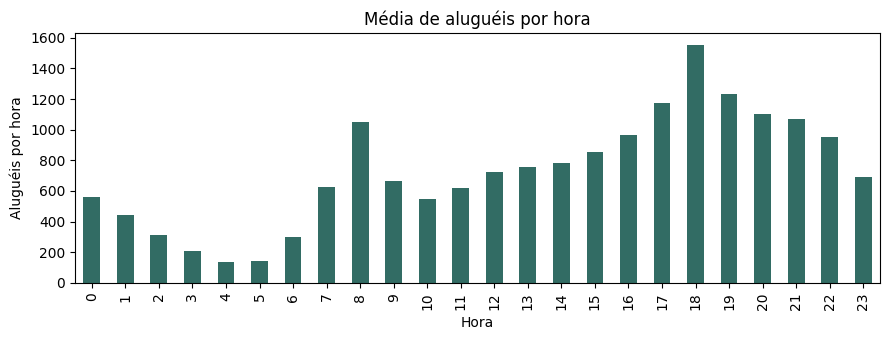

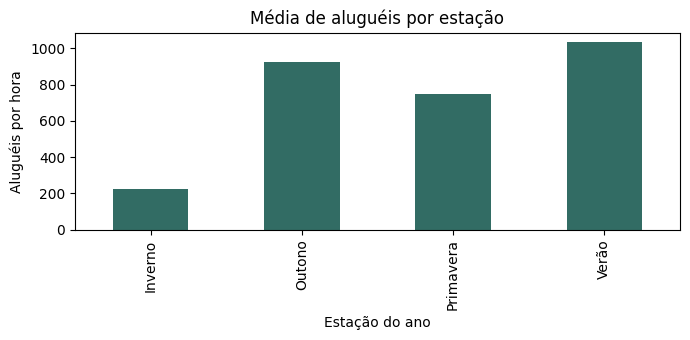

In [17]:
por_hora = df.groupby("Hora")["Alugueis"].agg(["mean", "median", "std"]).round(1)
por_estacao = df.groupby("Estacao")["Alugueis"].agg(["count", "mean", "median", "std"]).round(1)

display(por_hora.rename(columns={"mean": "Média", "median": "Mediana", "std": "Desvio-padrão"}))
display(por_estacao.rename(columns={"count": "Horas", "mean": "Média", "median": "Mediana", "std": "Desvio-padrão"}))

plt.figure(figsize=(9, 3.5))
por_hora["mean"].plot(kind="bar", color="#326C64")
plt.title("Média de aluguéis por hora")
plt.xlabel("Hora")
plt.ylabel("Aluguéis por hora")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3.5))
por_estacao["mean"].plot(kind="bar", color="#326C64")
plt.title("Média de aluguéis por estação")
plt.xlabel("Estação do ano")
plt.ylabel("Aluguéis por hora")
plt.tight_layout()
plt.show()

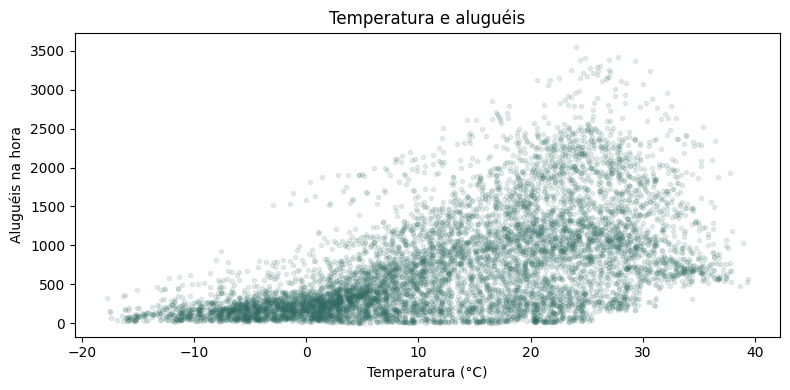

Correlação de Pearson: 0.563


In [18]:
plt.figure(figsize=(8, 4))
plt.scatter(df["Temperatura"], df["Alugueis"], alpha=0.12, s=9, color="#326C64")
plt.title("Temperatura e aluguéis")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Aluguéis na hora")
plt.tight_layout()
plt.show()

print("Correlação de Pearson:", round(df["Temperatura"].corr(df["Alugueis"]), 3))

## 4. Testes de hipóteses e intervalos de confiança

Para evitar comparar várias horas do mesmo dia como se fossem independentes, usamos a **média de aluguéis por hora de cada dia**, uma observação por dia.

- **H₀ 1:** a média nos dias com chuva é igual à média nos dias sem chuva.
- **H₀ 2:** a média nos fins de semana é igual à média nos dias úteis.

Aplicamos o **teste t de Welch** (bilateral, 5%), que não exige variâncias iguais. O intervalo de confiança de 95% estima a diferença das médias (**primeiro grupo menos segundo**). Dias próximos ainda podem ser correlacionados, por isso as conclusões devem ser tratadas como associações, não como efeitos causais.

In [19]:
diario = df.groupby("Data").agg(
    Media_alugueis=("Alugueis", "mean"),
    Temperatura=("Temperatura", "mean"),
    Chuva=("Chuva", "sum"),
    Fim_semana=("Fim_semana", "first")
).sort_index()
diario["Choveu"] = diario["Chuva"] > 0

def testar(nome, grupo1, grupo2):
    teste = stats.ttest_ind(grupo1, grupo2, equal_var=False)
    ic = teste.confidence_interval(confidence_level=0.95)
    return {
        "Comparação": nome,
        "Dias grupo 1": len(grupo1),
        "Dias grupo 2": len(grupo2),
        "Diferença das médias": grupo1.mean() - grupo2.mean(),
        "Graus de liberdade": teste.df,
        "p-valor": teste.pvalue,
        "IC 95% inferior": ic.low,
        "IC 95% superior": ic.high
    }

resultados = pd.DataFrame([
    testar("Com chuva - sem chuva",
           diario.loc[diario["Choveu"], "Media_alugueis"],
           diario.loc[~diario["Choveu"], "Media_alugueis"]),
    testar("Fim de semana - dia útil",
           diario.loc[diario["Fim_semana"], "Media_alugueis"],
           diario.loc[~diario["Fim_semana"], "Media_alugueis"])
])
display(resultados.round(3))

,Comparação,Dias grupo 1,Dias grupo 2,Diferença das médias,Graus de liberdade,p-valor,IC 95% inferior,IC 95% superior
0,Com chuva - sem chuva,100,253,-175.227,190.516,0.000,-267.967,-82.488
1,Fim de semana - dia útil,102,251,-64.987,189.116,0.181,-160.382,30.407


**Interpretação:** quando `p-valor < 0,05`, rejeitamos H₀ sob as condições do teste. Se o IC 95% da diferença inclui zero, não há evidência suficiente de diferença nesse nível de significância. O tamanho da diferença é relevante para avaliar utilidade prática, mesmo quando há significância estatística.

## 5. Regressão linear simples

Para que o modelo seja fácil de explicar, estimamos a **média diária de aluguéis por hora** a partir da **temperatura média do dia**:

\[\widehat{Y} = a + b \times \mathrm{Temperatura}\]

Separamos cronologicamente os primeiros 80% dos dias para treino e os últimos 20% para teste. Usamos `linregress` para estimar a reta, o coeficiente e seu intervalo de confiança. As previsões abaixo pressupõem que a temperatura do dia de teste seja conhecida; **não representam uma previsão meteorológica do futuro**.

In [20]:
corte = int(len(diario) * 0.8)
treino = diario.iloc[:corte]
teste = diario.iloc[corte:].copy()

modelo = stats.linregress(treino["Temperatura"], treino["Media_alugueis"])
teste["Previsto"] = (modelo.intercept + modelo.slope * teste["Temperatura"]).clip(lower=0)
teste["Referencia"] = treino["Media_alugueis"].mean()

intervalo_b = stats.t.interval(0.95, len(treino) - 2, loc=modelo.slope, scale=modelo.stderr)

def avaliar(nome, previsao):
    erro = teste["Media_alugueis"] - previsao
    return {
        "Modelo": nome,
        "MAE": erro.abs().mean(),
        "RMSE": (erro.pow(2).mean()) ** 0.5,
        "R² teste": 1 - erro.pow(2).sum() / ((teste["Media_alugueis"] - teste["Media_alugueis"].mean()) ** 2).sum()
    }

print("Equação: aluguéis/hora =", round(modelo.intercept, 2), "+", round(modelo.slope, 2), "× temperatura")
print("IC 95% do coeficiente de temperatura:", tuple(round(v, 2) for v in intervalo_b))
print("Treino:", treino.index.min().date(), "a", treino.index.max().date())
print("Teste:", teste.index.min().date(), "a", teste.index.max().date())

display(pd.DataFrame([
    avaliar("Média histórica (referência)", teste["Referencia"]),
    avaliar("Regressão linear", teste["Previsto"])
]).round(2))

Equação: aluguéis/hora = 342.63 + 26.85 × temperatura
IC 95% do coeficiente de temperatura: (np.float64(24.42), np.float64(29.29))
Treino: 2017-12-01 a 2018-09-10
Teste: 2018-09-11 a 2018-11-30


,Modelo,MAE,RMSE,R² teste
0,Média histórica (referência),280.75,339.74,-0.59
1,Regressão linear,284.94,315.56,-0.38


**MAE** é o erro absoluto médio em aluguéis por hora; **RMSE** penaliza erros grandes; **R² no teste** pode ser negativo se a previsão for ruim. Como a relação temperatura–demanda também depende de horário, estação e outros fatores, um modelo linear simples pode apresentar erros altos. O objetivo é demonstrar, avaliar e reconhecer as limitações da regressão.

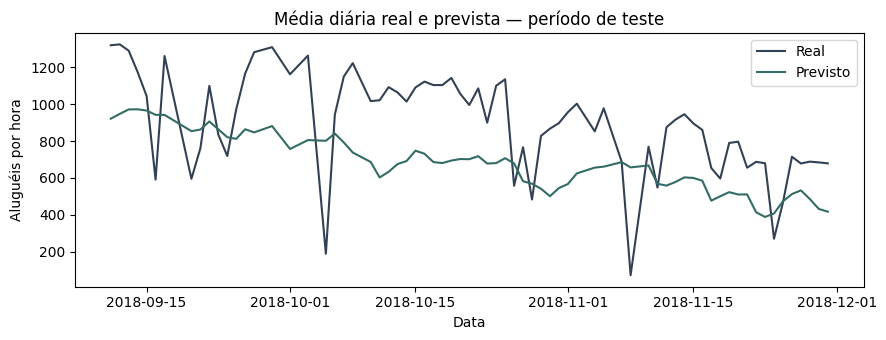

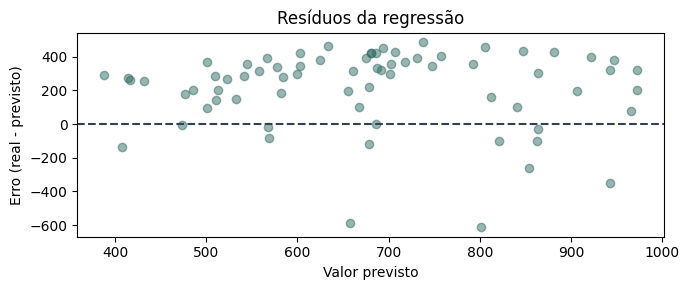

In [21]:
plt.figure(figsize=(9, 3.5))
plt.plot(teste.index, teste["Media_alugueis"], label="Real", color="#334155")
plt.plot(teste.index, teste["Previsto"], label="Previsto", color="#326C64")
plt.title("Média diária real e prevista — período de teste")
plt.xlabel("Data")
plt.ylabel("Aluguéis por hora")
plt.legend()
plt.tight_layout()
plt.show()

residuos = teste["Media_alugueis"] - teste["Previsto"]
plt.figure(figsize=(7, 3))
plt.scatter(teste["Previsto"], residuos, alpha=0.5, color="#326C64")
plt.axhline(0, color="#334155", linestyle="--")
plt.title("Resíduos da regressão")
plt.xlabel("Valor previsto")
plt.ylabel("Erro (real - previsto)")
plt.tight_layout()
plt.show()

## 6. Aplicação prática: horários prioritários

Como o arquivo **não indica estoque nem localização das bicicletas**, não podemos afirmar quantas bicicletas devem ser deslocadas. Uma recomendação viável é **priorizar atenção operacional aos três horários com maior média de aluguéis no treino**.

Avaliaremos essa regra nos dias de teste: qual parcela de todos os aluguéis ocorreu nesses horários e qual parcela das horas registradas eles representam? Isso é uma **simulação descritiva de prioridade**, não prova de melhoria efetiva do serviço.

In [22]:
base_treino = df[df["Data"].isin(treino.index)]
base_teste = df[df["Data"].isin(teste.index)]
prioritarios = base_treino.groupby("Hora")["Alugueis"].mean().nlargest(3).index.tolist()
selecao = base_teste[base_teste["Hora"].isin(prioritarios)]

print("Horários prioritários (definidos no treino):", sorted(prioritarios))
display(pd.DataFrame({
    "Indicador": ["Parcela de aluguéis no teste", "Parcela das horas observadas no teste"],
    "Percentual": [
        100 * selecao["Alugueis"].sum() / base_teste["Alugueis"].sum(),
        100 * len(selecao) / len(base_teste)
    ]
}).round(1))

Horários prioritários (definidos no treino): [17, 18, 19]


,Indicador,Percentual
0,Parcela de aluguéis no teste,22.9
1,Parcela das horas observadas no teste,12.6


## 7. Conclusão para a defesa oral

Após executar com o **CSV real**, registrem: (1) quais horários e estações tiveram maiores médias; (2) tamanho, direção, p-valor e IC das duas comparações; (3) equação, MAE, RMSE e R² da regressão versus referência; (4) a parcela de aluguéis nos horários prioritários.

**Limitações:** estudo observacional de apenas um ano; dependência entre datas próximas; relações não necessariamente lineares; desconhecimento de estoques e estações; previsões condicionadas à temperatura conhecida. Nenhuma diferença observada demonstra causalidade.

**Fontes:** Seoul Bike Sharing Demand, UCI Machine Learning Repository; lauda do Projeto de Modelagem Estatística da disciplina.